# TP "El Super Niño" — Notebook de código

**Modelación Numérica (CB-051) / Análisis Numérico I (9504) — FIUBA — 2.º cuatrimestre 2026 — Grupo N.º 1**
Integrantes: Ezequiel Ariel Miño (107646), Agustín Lucchelli (109337), Lorenzo Busato (110490).

Este notebook acompaña a `INFORME.md`. **Contiene todo el código que se usó** para obtener los números y **las 10 figuras del informe**, en el mismo orden en que aparecen allí. Cada sección explica qué se calcula y por qué, de modo que se pueda leer sin el informe al lado.

## Cómo usarlo

- Se ejecuta de arriba hacia abajo (*Kernel → Restart & Run All*). Solo necesita `numpy` y `matplotlib`.
- Las figuras se guardan en la carpeta `resultados/` con los mismos nombres que usa el informe.
- La grilla de la sección 3.3 simula 2.401 combinaciones con $h = 0{,}001$ y tarda unos minutos. Para una corrida rápida (grilla con $h = 0{,}01$) poner `RAPIDO = True` en la primera celda de código.

## Mapa de figuras

| Figura del informe | Archivo generado | Sección del notebook |
|---|---|---|
| Figura 1: autovalores del jacobiano y cotas de paso | `fig_2_1_autovalores.png` | 1.2 |
| Figura 2: $h_{crit}(t)$ y radio espectral de Floquet | `fig_1_4_jacobiano.png` | 1.2 |
| Figura 3: pasos estables e inestables | `fig_1_4_estabilidad.png` | 1.3 |
| Figura 4: Euler con $h = 0{,}1$ | `fig_2_1_euler_h01.png` | 1.4 |
| Figura 5: $T$, $H$, $P$ nominales, 60 meses | `fig_3_1_60meses.png` | 2.1 |
| Figura 6: último ciclo anual | `fig_3_1_ultimo_ciclo.png` | 2.1 |
| Figura 7: sensibilidad a $A$, $\beta$, $\gamma$, $\sigma$ | `fig_3_2_sensibilidad.png` | 2.2 |
| Figura 8: mapa de $S_P$ en el plano $(\gamma, A)$ | `fig_3_3_mapa_SP.png` | 2.3 |
| Figura 9: nominal vs. mayor severidad | `fig_3_4_comparacion.png` | 2.4 |
| Figura 10: último ciclo del escenario severo | `fig_3_4_ultimo_ciclo_severo.png` | 2.4 |

## 0. Modelo, parámetros y funciones comunes

El modelo simplificado de El Niño tiene tres variables: $T$ (anomalía de temperatura del mar), $H$ (humedad) y $P$ (precipitación):

$$\frac{dT}{dt} = R(t)\,T\left(1-\frac{T}{T_{max}}\right) - \alpha H, \qquad \frac{dH}{dt} = \beta T^2 - \gamma H P, \qquad \frac{dP}{dt} = \delta H^2 - \sigma P$$

con la excitación estacional $R(t) = R_{oce} + A\cos(\omega t - \pi)$, $\omega = 2\pi/12$. Condiciones iniciales $T(0)=1$, $H(0)=0$, $P(0)=0$ y $0 \le t \le 60$ meses.

La celda siguiente define los parámetros nominales, las constantes y el estilo de los gráficos.

In [1]:
import math, os, csv, itertools, time
import numpy as np
import matplotlib.pyplot as plt

RAPIDO = False          # True: la grilla de 2.3 usa h = 0,01 en vez de 0,001 (~10 veces más rápido)

# ---- Datos del problema (consigna) ----
PARAMS_NOMINALES = dict(
    Tmax=4.0,     # anomalía máxima sostenible           [°C]
    Roce=0.30,    # tasa intrínseca de calentamiento     [1/mes]
    alpha=0.05,   # enfriamiento por evaporación
    beta=0.20,    # eficiencia de evaporación
    gamma=0.10,   # consumo de humedad por precipitación
    delta=0.40,   # conversión de humedad a lluvia
    sigma=0.70,   # descarga / disipación                [1/mes]
    A=0.45,       # amplitud de la modulación estacional [1/mes]
)
OMEGA = 2.0 * math.pi / 12.0     # rad/mes (ciclo anual)
Y0 = (1.0, 0.0, 0.0)             # T(0), H(0), P(0)
T_FIN = 60.0                     # meses
T_ULTIMO_CICLO = 48.0            # último ciclo anual: 48 <= t <= 60
PERIODO = 12.0                   # meses
P = PARAMS_NOMINALES

# ---- Carpeta de salida y estilo de gráficos ----
DIR_RESULTADOS = "resultados"
os.makedirs(DIR_RESULTADOS, exist_ok=True)

C_T, C_H, C_P = "#2a78d6", "#eb6834", "#1baf7a"      # azul = T, naranja = H, verde = P
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE, BAND = "#e1e0d9", "#fcfcfb", "#ecebe6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "regular",
})
_trapecio = getattr(np, "trapezoid", None) or np.trapz   # np.trapezoid existe desde numpy 2.0

def guardar(fig, nombre):
    """Guarda la figura en resultados/ con el nombre que usa el informe y la muestra."""
    fig.savefig(os.path.join(DIR_RESULTADOS, nombre), dpi=160)
    plt.show()

### Integradores y jacobiano

- `euler(p, h)` es el **método de Euler explícito** $y_{n+1} = y_n + h\,f(t_n, y_n)$ con $y = [T, H, P]^T$. Si alguna variable supera $10^6$ en módulo se considera que la solución **diverge** (los valores físicos son de orden 1 a 10): se corta y el resto de la trayectoria se completa con `NaN`.
- `rk4(p, h)` es Runge-Kutta de orden 4. **No se usa para resolver el problema**, solo como control independiente (órbita "exacta" para evaluar el jacobiano y verificación del paso de la Parte 2).
- `jacobiano(...)` es la matriz $J = \partial f/\partial y$ que se deduce en la sección 1.1.

In [2]:
def rhs(t, T, H, P_, p):
    """Lado derecho f(t, y) del sistema; devuelve (dT/dt, dH/dt, dP/dt)."""
    R = p["Roce"] + p["A"] * math.cos(OMEGA * t - math.pi)
    dT = R * T * (1.0 - T / p["Tmax"]) - p["alpha"] * H
    dH = p["beta"] * T * T - p["gamma"] * H * P_
    dP = p["delta"] * H * H - p["sigma"] * P_
    return dT, dH, dP


def euler(p, h, t_fin=T_FIN, y0=Y0, limite=1e6):
    """Euler explícito. Devuelve (t, y) con y de forma (n+1, 3) = columnas T, H, P.
    Si h no divide a t_fin, el último paso es más corto para terminar en t_fin."""
    n = int(math.ceil(t_fin / h - 1e-9))
    h_ult = t_fin - (n - 1) * h
    y = np.full((n + 1, 3), np.nan)
    T, H, P_ = y0
    y[0] = y0
    Tmax, Roce, al, be, ga, de, si, A = (p["Tmax"], p["Roce"], p["alpha"], p["beta"],
                                         p["gamma"], p["delta"], p["sigma"], p["A"])
    cos = math.cos
    for k in range(n):
        hk = h_ult if k == n - 1 else h
        R = Roce + A * cos(OMEGA * (k * h) - math.pi)
        dT = R * T * (1.0 - T / Tmax) - al * H
        dH = be * T * T - ga * H * P_
        dP = de * H * H - si * P_
        T, H, P_ = T + hk * dT, H + hk * dH, P_ + hk * dP
        if not (abs(T) < limite and abs(H) < limite and abs(P_) < limite):
            break
        y[k + 1] = (T, H, P_)
    t = np.arange(n + 1) * h
    t[-1] = t_fin
    return t, y


def diverge(y):
    """True si la trayectoria tiene NaN (el integrador cortó por divergencia)."""
    return bool(np.isnan(y).any())


def rk4(p, h, t_fin=T_FIN, y0=Y0):
    """Runge-Kutta de orden 4 (solo verificación independiente)."""
    n = int(round(t_fin / h))
    y = np.empty((n + 1, 3))
    y[0] = y0
    T, H, P_ = y0
    h2, h6 = h / 2.0, h / 6.0
    for k in range(n):
        t = k * h
        a1, b1, c1 = rhs(t, T, H, P_, p)
        a2, b2, c2 = rhs(t + h2, T + h2 * a1, H + h2 * b1, P_ + h2 * c1, p)
        a3, b3, c3 = rhs(t + h2, T + h2 * a2, H + h2 * b2, P_ + h2 * c2, p)
        a4, b4, c4 = rhs(t + h, T + h * a3, H + h * b3, P_ + h * c3, p)
        T += h6 * (a1 + 2 * a2 + 2 * a3 + a4)
        H += h6 * (b1 + 2 * b2 + 2 * b3 + b4)
        P_ += h6 * (c1 + 2 * c2 + 2 * c3 + c4)
        y[k + 1] = (T, H, P_)
    return np.arange(n + 1) * h, y


def jacobiano(t, T, H, P_, p):
    """Matriz jacobiana df/dy evaluada en (t, T, H, P)."""
    R = p["Roce"] + p["A"] * math.cos(OMEGA * t - math.pi)
    return np.array([
        [R * (1.0 - 2.0 * T / p["Tmax"]), -p["alpha"], 0.0],
        [2.0 * p["beta"] * T, -p["gamma"] * P_, -p["gamma"] * H],
        [0.0, 2.0 * p["delta"] * H, -p["sigma"]],
    ])

### Indicadores del último ciclo anual (Parte 2)

Debido al transitorio de las condiciones iniciales, los indicadores se calculan **solo con el último ciclo, $48 \le t \le 60$**:

$$S_P = \frac{P_{max} - P_{min}}{P_{med}}, \qquad \Delta t_{TP} = t_{P,max} - t_{T,max}$$

- $P_{med}$ es el promedio temporal (integral trapezoidal dividida por la duración del ciclo).
- Los instantes de máximo se ubican sobre la grilla y se **refinan con una parábola por tres puntos** (así el error es mucho menor que $h$).
- Si el máximo de $P$ ocurre antes que el de $T$ dentro de la ventana, el "máximo posterior" es el del ciclo siguiente: se suma el período de 12 meses.
- También se mide cuánto difiere el último ciclo del anterior, para verificar que el régimen anual **se repite**.

In [3]:
def tiempo_del_maximo(tc, v):
    """Instante del máximo de v sobre tc; si es interior se refina con una parábola por 3 puntos."""
    i = int(np.argmax(v))
    interior = 0 < i < len(v) - 1
    if interior:
        a, b, c = v[i - 1], v[i], v[i + 1]
        den = a - 2.0 * b + c
        if den < 0.0:
            return tc[i] + 0.5 * (a - c) / den * (tc[1] - tc[0]), True
    return tc[i], interior


def indicadores(t, y, t_ini=T_ULTIMO_CICLO, periodo=PERIODO):
    """SP, dtTP y estadísticos de P usando únicamente t_ini <= t <= t_fin."""
    i0 = int(np.searchsorted(t, t_ini - 1e-9))
    tc, T, P_ = t[i0:], y[i0:, 0], y[i0:, 2]
    Pmax, Pmin = float(P_.max()), float(P_.min())
    Pmed = float(_trapecio(P_, tc) / (tc[-1] - tc[0]))     # promedio temporal (trapecios)
    SP = (Pmax - Pmin) / Pmed
    tT, ok_T = tiempo_del_maximo(tc, T)
    tP, ok_P = tiempo_del_maximo(tc, P_)
    dt = tP - tT
    if dt < 0.0:                       # el máximo posterior de P es el del ciclo siguiente
        dt += periodo
    i_prev = int(np.searchsorted(t, t_ini - periodo - 1e-9))
    prev, last = y[i_prev:i0 + 1], y[i0:]
    desvio = np.abs(last - prev).max(axis=0) if len(prev) == len(last) else None
    return dict(Pmax=Pmax, Pmin=Pmin, Pmed=Pmed, SP=SP, tT=tT, Tpico=float(T.max()),
                tP=tP, dtTP=dt, desvio_periodicidad=desvio)

---
# Parte 1: Convergencia, orden y estabilidad del método de Euler explícito

## 1.1. Forma matricial y jacobiano

Con $\mathbf{y} = [T, H, P]^T$ el sistema es $\dot{\mathbf{y}} = \mathbf{f}(t, \mathbf{y})$ y Euler explícito resulta

$$\mathbf{y}_{n+1} = \mathbf{y}_n + h\,\mathbf{f}(t_n, \mathbf{y}_n).$$

El **jacobiano** $J = \partial \mathbf{f}/\partial \mathbf{y}$ describe cómo responde el sistema a perturbaciones pequeñas:

$$J(t,T,H,P) = \begin{pmatrix} R(t)\left(1-\dfrac{2T}{T_{max}}\right) & -\alpha & 0 \\[2mm] 2\beta T & -\gamma P & -\gamma H \\[2mm] 0 & 2\delta H & -\sigma \end{pmatrix}$$

**Criterio de estabilidad de Euler.** Para cada autovalor $\lambda$ de $J$, el factor de amplificación es $G = 1 + h\lambda$ y se necesita $|G| \le 1$. Para autovalores reales negativos esto da $h \le 2/|\lambda|$; en general, para $\mathrm{Re}(\lambda) < 0$:

$$h < h_{crit}(\lambda) = \frac{-2\,\mathrm{Re}(\lambda)}{|\lambda|^2}.$$

Un autovalor con parte real positiva es crecimiento real del sistema, no inestabilidad numérica, por lo que el criterio solo se aplica a los modos con $\mathrm{Re}(\lambda) < 0$.

Antes de usar `jacobiano()` se verifica que coincida con una derivada numérica (diferencias centradas) de `rhs`.

In [4]:
# Verificación: jacobiano analítico vs. diferencias finitas centradas de rhs
t_, y_ = 7.3, np.array([2.1, 1.7, 3.2])
J_an = jacobiano(t_, *y_, P)
J_num = np.zeros((3, 3))
for j in range(3):
    e = np.zeros(3); e[j] = 1e-6
    fp = np.array(rhs(t_, *(y_ + e), P)); fm = np.array(rhs(t_, *(y_ - e), P))
    J_num[:, j] = (fp - fm) / 2e-6
print("máxima diferencia analítico vs. numérico:", np.abs(J_an - J_num).max())

máxima diferencia analítico vs. numérico: 1.6073253839010704e-10


## 1.2. Autovalores sobre la solución y referencia teórica (Figuras 1 y 2)

### Figura 1: autovalores del jacobiano y cotas locales de paso

Se resuelve el problema con un paso chico ($h = 0{,}01$), se evalúa $J$ en cada instante sobre esa solución y se calculan sus autovalores. A la izquierda se grafican los autovalores (hay uno real y un par complejo conjugado). A la derecha, la cota de paso con los autovalores "congelados" en cada instante, con dos criterios: $2/|\lambda_{max}|$ (el del texto del grupo) y $-2\,\mathrm{Re}(\lambda)/|\lambda|^2$ (modos con $\mathrm{Re}<0$). Se marcan 2,35 y el último paso estable observado (1,25).

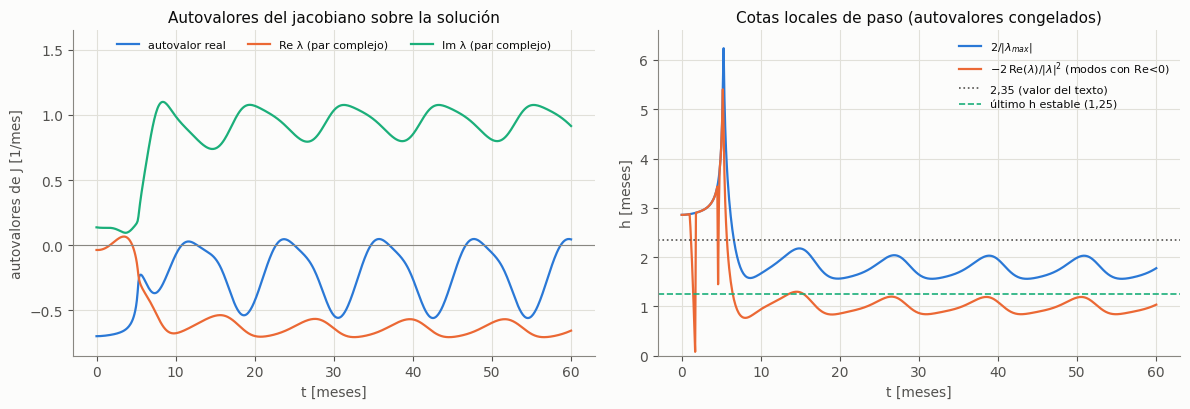

2/|λmax| en todo el intervalo: entre 1.56 y 6.24
2/|λmax| en el último ciclo (48-60): entre 1.56 y 2.03


In [5]:
t_s, y_s = euler(P, 0.01)
paso = 10
tt = t_s[::paso]
ev = np.array([np.linalg.eigvals(jacobiano(t_s[k], *y_s[k], P)) for k in range(0, len(t_s), paso)])

h_2_sobre_lmax = 2.0 / np.abs(ev).max(axis=1)
h_crit = np.full(len(tt), np.inf)
for i, e in enumerate(ev):
    for lam in e:
        if lam.real < 0:
            h_crit[i] = min(h_crit[i], -2.0 * lam.real / abs(lam) ** 2)

real_ = np.array([e[np.argmin(np.abs(e.imag))].real for e in ev])   # autovalor real
cplx = np.array([e[np.argmax(e.imag)] for e in ev])                  # par complejo (parte Im > 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(tt, real_, color=C_T, lw=1.6, label="autovalor real")
ax[0].plot(tt, cplx.real, color=C_H, lw=1.6, label="Re λ (par complejo)")
ax[0].plot(tt, cplx.imag, color=C_P, lw=1.6, label="Im λ (par complejo)")
ax[0].axhline(0, color=MUTED, lw=0.8)
ax[0].set_xlabel("t [meses]"); ax[0].set_ylabel("autovalores de J [1/mes]")
ax[0].set_title("Autovalores del jacobiano sobre la solución")
ax[0].set_ylim(-0.85, 1.65); ax[0].legend(frameon=False, loc="upper center", ncol=3, fontsize=8)

ax[1].plot(tt, h_2_sobre_lmax, color=C_T, lw=1.6, label=r"$2/|\lambda_{max}|$")
ax[1].plot(tt, np.minimum(h_crit, 6.5), color=C_H, lw=1.6,
           label=r"$-2\,\mathrm{Re}(\lambda)/|\lambda|^2$ (modos con Re<0)")
ax[1].axhline(2.35, color=INK2, ls=":", lw=1.2, label="2,35 (valor del texto)")
ax[1].axhline(1.25, color=C_P, ls="--", lw=1.2, label="último h estable (1,25)")
ax[1].set_ylim(0, 6.6); ax[1].set_xlabel("t [meses]"); ax[1].set_ylabel("h [meses]")
ax[1].set_title("Cotas locales de paso (autovalores congelados)")
ax[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
guardar(fig, "fig_2_1_autovalores.png")

ult = tt >= 48
print("2/|λmax| en todo el intervalo: entre %.2f y %.2f" % (h_2_sobre_lmax.min(), h_2_sobre_lmax.max()))
print("2/|λmax| en el último ciclo (48-60): entre %.2f y %.2f" % (h_2_sobre_lmax[ult].min(), h_2_sobre_lmax[ult].max()))

### Figura 2: jacobiano sobre la órbita anual y multiplicadores de Floquet

Las cotas "congeladas" son solo locales: el sistema es no lineal y depende del tiempo. Una referencia más apropiada para un régimen periódico es **linealizar el mapa de Euler a lo largo de un ciclo anual** $[48, 60]$:

$$M = \prod_{n} \left(I + h\,J_n\right)$$

y estudiar su radio espectral $\rho(M)$ (multiplicadores de Floquet). La órbita anual es numéricamente estable mientras $\rho(M) < 1$.

Para evaluar $J$ se usa la órbita "exacta" dada por RK4 con $h = 0{,}005$. Además se busca el **umbral experimental de divergencia** de Euler por bisección (un paso diverge si alguna variable supera $10^6$), para marcarlo en la figura.

Umbral experimental de divergencia: h* ≈ 1.25029 meses
Barrido de 1,25 a 1,40 de a 0,01: solo es estable h = 1,25: True

Autovalores del jacobiano sobre la solución:
  t =    0:  -0.7000;  -0.0375+0.1364i;  -0.0375-0.1364i
  t =    6:  -0.2590;  -0.3567+0.5273i;  -0.3567-0.5273i
  t =   12:  0.0235;  -0.6283+0.8561i;  -0.6283-0.8561i
  t =   60:  0.0437;  -0.6571+0.9144i;  -0.6571-0.9144i

h_crítico puntual en t = 60 (par complejo -0.65709 ± 0.91443i): 1.0365 meses


h_crítico puntual, mínimo sobre toda la trayectoria: 0.079 en t = 1.70 (transitorio)
h_crítico puntual en el último ciclo (48-60): entre 0.842 y 1.191



Radio espectral con la solución exacta (h -> 0): 0.0687  (<1: la órbita anual es estable)
    N         h       rho(M)
   20    0.6000       0.0445
   19    0.6316       0.0432
   18    0.6667       0.0578
   17    0.7059       0.0855
   16    0.7500       0.1319
   15    0.8000       0.2127
   14    0.8571       0.3590
   13    0.9231       0.6342
   12    1.0000       1.1688
   11    1.0909       2.2312
   10    1.2000       4.3565
    9    1.3333       8.5358
    8    1.5000      16.3477
    7    1.7143      29.5836
rho >= 1 desde h = 1.0000


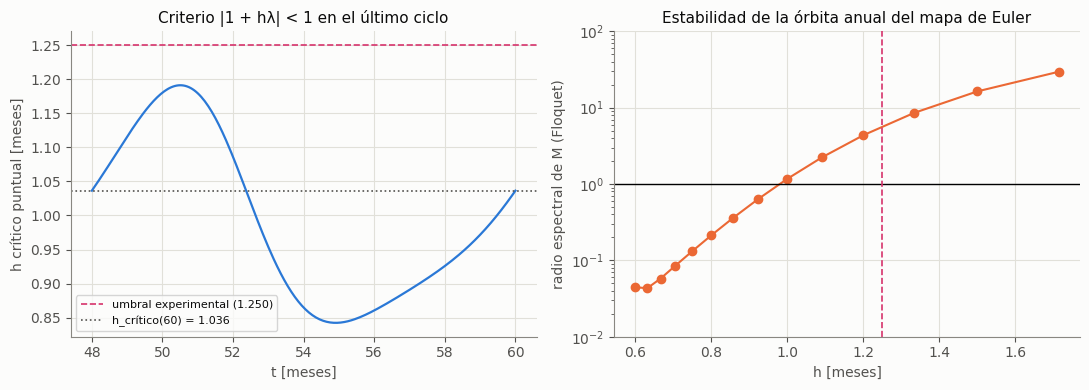

In [6]:
def divergencia_en(h):
    t, y = euler(P, h)
    return diverge(y)

# --- Umbral experimental por bisección entre 1,25 (estable) y 1,26 (diverge) ---
lo, hi = 1.25, 1.26
assert not divergencia_en(lo) and divergencia_en(hi)
for _ in range(40):
    mid = 0.5 * (lo + hi)
    if divergencia_en(mid): hi = mid
    else: lo = mid
UMBRAL = lo
print("Umbral experimental de divergencia: h* ≈ %.5f meses" % UMBRAL)
scan = [(round(h, 3), divergencia_en(h)) for h in np.arange(1.25, 1.401, 0.01)]
print("Barrido de 1,25 a 1,40 de a 0,01: solo es estable h = 1,25:",
      (not scan[0][1]) and all(d for h, d in scan if h >= 1.26))


def h_critico_puntual(autovalores):
    """Euler: |1 + h*lam| < 1  ->  h < -2 Re(lam)/|lam|^2, solo si Re(lam) < 0."""
    v = [-2.0 * l.real / abs(l) ** 2 for l in autovalores if l.real < 0.0]
    return min(v) if v else math.inf

# --- Órbita "exacta" (RK4 fino) para evaluar el jacobiano ---
t_o, y_o = rk4(P, 0.005)
orbita = lambda t: [float(np.interp(t, t_o, y_o[:, j])) for j in range(3)]

print("\nAutovalores del jacobiano sobre la solución:")
for tt_ in (0.0, 6.0, 12.0, 60.0):
    ev_ = sorted(np.linalg.eigvals(jacobiano(tt_, *orbita(tt_), P)), key=lambda z: (abs(z.imag), z.real))
    print("  t = %4g:  " % tt_ + ";  ".join("%.4f" % z.real + ("%+.4fi" % z.imag if abs(z.imag) > 1e-9 else "") for z in ev_))

ev60 = np.linalg.eigvals(jacobiano(60.0, *orbita(60.0), P))
comp = [z for z in ev60 if abs(z.imag) > 1e-9][0]
hc60 = -2 * comp.real / abs(comp) ** 2
print("\nh_crítico puntual en t = 60 (par complejo %.5f ± %.5fi): %.4f meses" % (comp.real, abs(comp.imag), hc60))

tg = np.arange(0.0, 60.0 + 1e-9, 0.05)
hc = np.array([h_critico_puntual(np.linalg.eigvals(jacobiano(t, *orbita(t), P))) for t in tg])
ultg = tg >= 48.0
i_min = int(np.argmin(hc))
print("h_crítico puntual, mínimo sobre toda la trayectoria: %.3f en t = %.2f (transitorio)" % (hc.min(), tg[i_min]))
print("h_crítico puntual en el último ciclo (48-60): entre %.3f y %.3f" % (hc[ultg].min(), hc[ultg].max()))

# --- Multiplicadores de Floquet del mapa de Euler linealizado en [48, 60] ---
def rho(N):
    hh = 12.0 / N
    M = np.eye(3)
    for n in range(N):
        t = 48.0 + n * hh
        M = (np.eye(3) + hh * jacobiano(t, *orbita(t), P)) @ M
    return float(max(abs(np.linalg.eigvals(M)))), hh

print("\nRadio espectral con la solución exacta (h -> 0): %.4f  (<1: la órbita anual es estable)" % rho(2400)[0])
print("%5s %9s %12s" % ("N", "h", "rho(M)"))
fl = []
for N in range(20, 6, -1):
    r_, hh = rho(N)
    fl.append((hh, r_))
    print("%5d %9.4f %12.4f" % (N, hh, r_))
cruce = [f for f in fl if f[1] >= 1.0]
print("rho >= 1 desde h = %.4f" % min(f[0] for f in cruce))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tg[ultg], hc[ultg], color=C_T, lw=1.6)
ax[0].axhline(UMBRAL, color="#d6336c", ls="--", lw=1.2, label="umbral experimental (%.3f)" % UMBRAL)
ax[0].axhline(hc60, color=INK2, ls=":", lw=1.2, label="h_crítico(60) = %.3f" % hc60)
ax[0].set_xlabel("t [meses]"); ax[0].set_ylabel("h crítico puntual [meses]")
ax[0].set_title("Criterio |1 + hλ| < 1 en el último ciclo"); ax[0].legend(fontsize=8)
ax[1].semilogy([f[0] for f in fl], [f[1] for f in fl], "o-", color=C_H)
ax[1].axhline(1.0, color="k", lw=1); ax[1].axvline(UMBRAL, color="#d6336c", ls="--", lw=1.2)
ax[1].set_xlabel("h [meses]"); ax[1].set_ylabel("radio espectral de M (Floquet)")
ax[1].set_title("Estabilidad de la órbita anual del mapa de Euler"); ax[1].set_ylim(0.01, 100)
fig.tight_layout()
guardar(fig, "fig_1_4_jacobiano.png")

**Lectura.** La teoría lineal predice que la órbita anual de Euler pierde estabilidad alrededor de $h \approx 1{,}0$ (el radio espectral cruza 1 entre $h = 0{,}92$ y $h = 1{,}00$), coherente con $h_{crit}(60) \approx 1{,}04$. Es una **referencia**, no una garantía: el sistema es no lineal y no autónomo.

## 1.3. Estabilidad experimental (Figura 3)

El grupo determinó experimentalmente que el paso crítico de Euler es aproximadamente **1,26 meses**: con $h = 1{,}25$ la simulación completa los 60 meses, y con $h = 1{,}26$ la solución explota (la bisección de la sección anterior ubica el umbral en $h^* \approx 1{,}2503$).

La Figura 3 muestra a la izquierda soluciones con pasos estables, al centro soluciones inestables (eje recortado) y a la derecha el error en el borde de estabilidad. Para dibujar la curva de "referencia" (negra) y el error del panel derecho se usa una solución de Euler con $h_{ref} = 0{,}0001$ (600.000 pasos), de error despreciable frente a los de estas discretizaciones.

Referencia fina: h = 0.0001 -> 600000 pasos
     h     estado     Err [°C]   detalle
   0.8    estable       0.3962   T entre 0.83 y 3.64
     1    estable       0.4946   T entre 0.82 y 3.70
   1.2    estable       0.6065   T entre 0.80 y 3.77
  1.25    estable       0.6153   T entre 0.80 y 3.84
  1.26    DIVERGE            -   supera 1e6 en t ≈ 44.1 meses
   1.4    DIVERGE            -   supera 1e6 en t ≈ 28.0 meses
   1.6    DIVERGE            -   supera 1e6 en t ≈ 20.8 meses
   3.2    DIVERGE            -   supera 1e6 en t ≈ 25.6 meses
   6.4    DIVERGE            -   supera 1e6 en t ≈ 44.8 meses


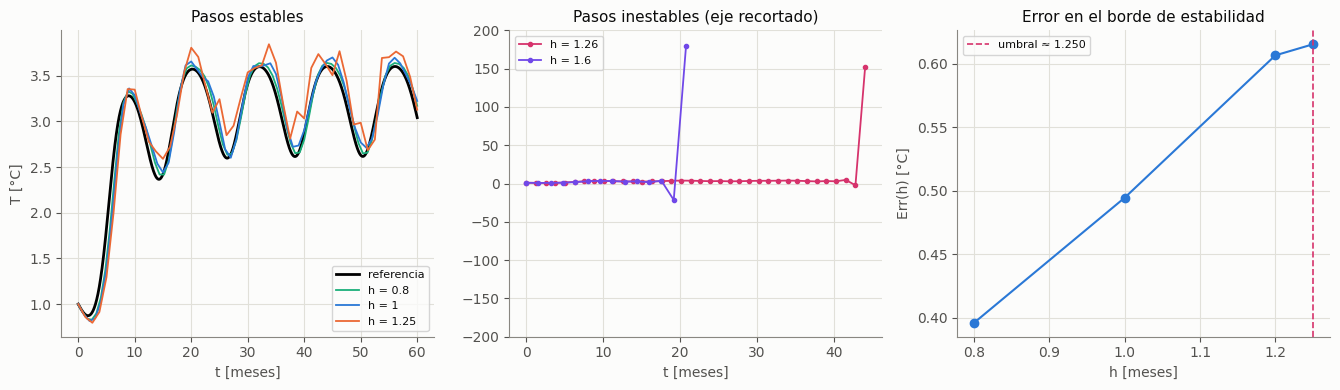

In [7]:
H_REF_FINO = 0.0001
t_fino, y_fino = euler(P, H_REF_FINO)
print("Referencia fina: h = %g -> %d pasos" % (H_REF_FINO, len(t_fino) - 1))

def err_vs(h, t_ref, y_ref, h_ref):
    """Err(h) = max |T_h - T_ref| en los nodos de h (todos son nodos de la referencia)."""
    t, y = euler(P, h)
    if diverge(y):
        return None, None
    r = int(round(h / h_ref))
    e = np.abs(y[:, 0] - y_ref[::r, 0][:len(t)])
    return float(e.max()), float(t[int(np.argmax(e))])

filas = []
print("%6s %10s %12s   %s" % ("h", "estado", "Err [°C]", "detalle"))
for h in [0.8, 1.0, 1.2, 1.25, 1.26, 1.4, 1.6, 3.2, 6.4]:
    t, y = euler(P, h)
    if diverge(y):
        i = int(np.argmax(np.isnan(y[:, 0])))
        print("%6g %10s %12s   supera 1e6 en t ≈ %.1f meses" % (h, "DIVERGE", "-", t[i]))
    else:
        e, _ = err_vs(h, t_fino, y_fino, H_REF_FINO)
        filas.append((h, e))
        print("%6g %10s %12.4f   T entre %.2f y %.2f" % (h, "estable", e, y[:, 0].min(), y[:, 0].max()))

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4))
ax[0].plot(t_fino, y_fino[:, 0], "k", lw=2, label="referencia")
for h, col in zip((0.8, 1.0, 1.25), ("#1baf7a", "#2a78d6", "#eb6834")):
    t, y = euler(P, h)
    ax[0].plot(t, y[:, 0], color=col, lw=1.3, label="h = %g" % h)
ax[0].set_xlabel("t [meses]"); ax[0].set_ylabel("T [°C]"); ax[0].set_title("Pasos estables"); ax[0].legend(fontsize=8)
for h, col in zip((1.26, 1.6), ("#d6336c", "#7048e8")):
    t, y = euler(P, h, limite=1e12)
    ax[1].plot(t, y[:, 0], color=col, lw=1.3, marker=".", label="h = %g" % h)
ax[1].set_ylim(-200, 200); ax[1].set_xlabel("t [meses]")
ax[1].set_title("Pasos inestables (eje recortado)"); ax[1].legend(fontsize=8)
ax[2].plot([f[0] for f in filas], [f[1] for f in filas], "o-", color=C_T)
ax[2].axvline(UMBRAL, color="#d6336c", ls="--", lw=1.2, label="umbral ≈ %.3f" % UMBRAL)
ax[2].set_xlabel("h [meses]"); ax[2].set_ylabel("Err(h) [°C]")
ax[2].set_title("Error en el borde de estabilidad"); ax[2].legend(fontsize=8)
fig.tight_layout()
guardar(fig, "fig_1_4_estabilidad.png")

## 1.4. Solución de referencia del grupo, $h_{ref} = 0{,}1$ (Figura 4)

En función del análisis de estabilidad, el grupo adoptó como paso de referencia $h_{ref} = 0{,}1$ meses, que es aproximadamente el 7,94 % del paso crítico experimental (1,26). Con 60 meses de intervalo, la cantidad de pasos es

$$N = \frac{60}{0{,}1} = 600.$$

La Figura 4 muestra la solución de Euler con ese paso: tras un transitorio de 2 a 3 años las tres variables se repiten cada 12 meses.

h_ref = 0.1 -> N = 600 pasos | 0,1 / 1,26 = 7.94 %


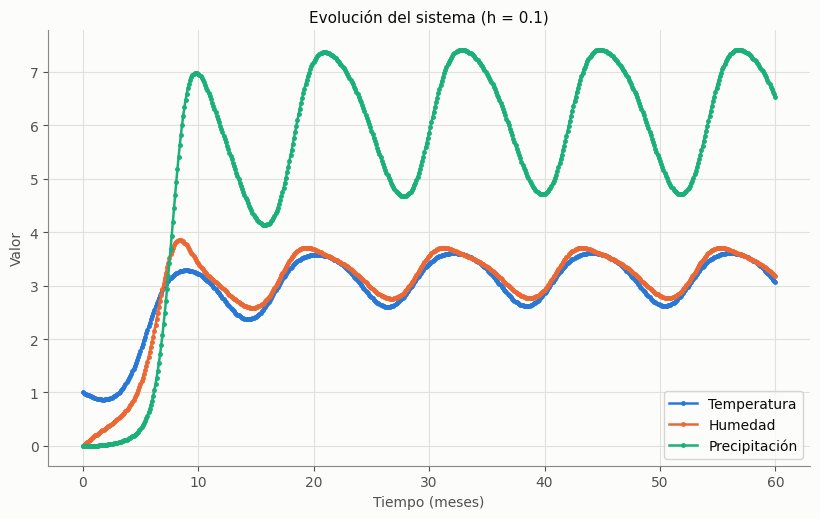

In [8]:
H_REF = 0.1
t_ref, y_ref = euler(P, H_REF)
print("h_ref = %g -> N = %d pasos" % (H_REF, len(t_ref) - 1), "| 0,1 / 1,26 = %.2f %%" % (100 * 0.1 / 1.26))

fig, ax = plt.subplots(figsize=(8.3, 5.3))
for j, (nom, col) in enumerate([("Temperatura", C_T), ("Humedad", C_H), ("Precipitación", C_P)]):
    ax.plot(t_ref, y_ref[:, j], "-o", color=col, ms=2.5, lw=1.8, label=nom)
ax.set_xlabel("Tiempo (meses)"); ax.set_ylabel("Valor")
ax.set_title("Evolución del sistema (h = 0.1)"); ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "fig_2_1_euler_h01.png")

## 1.5. Errores con sucesivos pasos $h$ y orden de convergencia (secciones 2.2 y 2.3 del informe)

Con la referencia $h_{ref} = 0{,}1$ se resolvió de nuevo con $h = 0{,}2;\ 0{,}4;\ 0{,}8$ y se cuantificó el error con el máximo error absoluto de $T$ sobre todo el intervalo:

$$Err(h) = \max_{0 \le t \le 60} \left| T_h(t) - T_{ref}(t) \right|$$

El orden observado entre pasos consecutivos es

$$p = \frac{\log\left(Err(2h)/Err(h)\right)}{\log 2},$$

y el valor esperado para Euler explícito (error global $O(h)$) es $p = 1$. No se puede calcular $p_1$ (entre $h = 0{,}1$ y $0{,}2$) porque el error de la referencia respecto de sí misma es nulo.

In [9]:
errs01 = {}
print("%6s %16s %20s" % ("h", "Err(h) [°C]", "t del error máx"))
for h in (0.2, 0.4, 0.8):
    e, te = err_vs(h, t_ref, y_ref, H_REF)
    errs01[h] = e
    print("%6g %16.6f %20.1f" % (h, e, te))

p2 = math.log(errs01[0.4] / errs01[0.2]) / math.log(2)
p3 = math.log(errs01[0.8] / errs01[0.4]) / math.log(2)
print("\np2 (h = 0,2 -> 0,4) = %.6f" % p2)
print("p3 (h = 0,4 -> 0,8) = %.6f" % p3)
print("Valor esperado para Euler explícito: p = 1")

     h      Err(h) [°C]      t del error máx
   0.2         0.047374                  5.4
   0.4         0.144940                  5.6
   0.8         0.351445                  5.6

p2 (h = 0,2 -> 0,4) = 1.613284
p3 (h = 0,4 -> 0,8) = 1.277843
Valor esperado para Euler explícito: p = 1


## 1.6. Paso temporal aumentado (sección 2.4 del informe)

Se duplicó el paso sucesivamente: $h = 0{,}1;\ 0{,}2;\ 0{,}4;\ 0{,}8;\ 1{,}6;\ 3{,}2;\ 6{,}4$ meses. Hasta $h = 0{,}8$ la simulación completa los 60 meses y el error crece de forma gradual (**error de discretización**). Con $h \ge 1{,}6$ las variables crecen de manera abrupta y descontrolada, y la simulación no puede completar los 60 meses (**inestabilidad numérica**).

In [10]:
print("%6s %10s %14s   %s" % ("h", "estado", "Err [°C]", "detalle"))
for h in (0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4):
    t, y = euler(P, h)
    if diverge(y):
        i = int(np.argmax(np.isnan(y[:, 0])))
        print("%6g %10s %14s   supera 1e6 en t ≈ %.1f meses (no completa los 60 meses)" % (h, "DIVERGE", "-", t[i]))
    else:
        e, _ = err_vs(h, t_ref, y_ref, H_REF)
        print("%6g %10s %14.6f   completa los 60 meses" % (h, "estable", e))

     h     estado       Err [°C]   detalle
   0.1    estable       0.000000   completa los 60 meses
   0.2    estable       0.047374   completa los 60 meses
   0.4    estable       0.144940   completa los 60 meses
   0.8    estable       0.351445   completa los 60 meses
   1.6    DIVERGE              -   supera 1e6 en t ≈ 20.8 meses (no completa los 60 meses)
   3.2    DIVERGE              -   supera 1e6 en t ≈ 25.6 meses (no completa los 60 meses)
   6.4    DIVERGE              -   supera 1e6 en t ≈ 44.8 meses (no completa los 60 meses)


**Error de discretización vs. inestabilidad numérica.** El primero es la diferencia entre la solución aproximada y la de referencia, y aumenta gradualmente con el paso. La inestabilidad se manifiesta como un crecimiento abrupto y descontrolado de los valores, de modo que la solución deja de representar el comportamiento del sistema.

### Anexo de la Parte 1: verificación con una referencia más fina

Con $h_{ref} = 0{,}1$ resultan órdenes $p_2 \approx 1{,}61$ y $p_3 \approx 1{,}28$, mayores que 1. La explicación que ya se menciona en el informe es que Euler con $h = 0{,}1$ tiene su propio error respecto de la solución exacta. Para comprobarlo, la celda siguiente repite el cálculo con la referencia fina $h_{ref} = 0{,}0001$ de la sección 1.3: el error de la propia referencia $h = 0{,}1$ ($Err(0{,}1) \approx 0{,}046$ °C) es comparable al que se quiere medir en $h = 0{,}2$, y con la referencia fina el orden observado se acerca al valor teórico $p = 1$.

In [11]:
HS = [0.025, 0.05, 0.1, 0.2, 0.4, 0.8]
errs_fino = {}
for h in HS:
    errs_fino[h], _ = err_vs(h, t_fino, y_fino, H_REF_FINO)

t_fino2, y_fino2 = euler(P, H_REF_FINO / 2)
print("Control: max|T(h_ref) - T(h_ref/2)| = %.2e °C (error de la referencia fina)\n" % np.abs(y_fino[:, 0] - y_fino2[::2, 0]).max())

print("%8s %14s" % ("h", "Err(h) [°C]"))
for h in HS:
    print("%8g %14.6f" % (h, errs_fino[h]))
print("\n%14s %12s %12s %9s" % ("h -> 2h", "Err(h)", "Err(2h)", "p"))
ps = []
for a, b in zip(HS[:-1], HS[1:]):
    p_ = math.log(errs_fino[b] / errs_fino[a]) / math.log(2)
    ps.append(p_)
    print("%6g -> %-5g %12.6f %12.6f %9.4f" % (a, b, errs_fino[a], errs_fino[b], p_))
print("\np medio = %.4f (esperado para Euler: p = 1)" % np.mean(ps))

Control: max|T(h_ref) - T(h_ref/2)| = 2.28e-05 °C (error de la referencia fina)

       h    Err(h) [°C]
   0.025       0.011393
    0.05       0.022904
     0.1       0.046135
     0.2       0.093319
     0.4       0.189660
     0.8       0.396165

       h -> 2h       Err(h)      Err(2h)         p
 0.025 -> 0.05      0.011393     0.022904    1.0075
  0.05 -> 0.1       0.022904     0.046135    1.0103
   0.1 -> 0.2       0.046135     0.093319    1.0163
   0.2 -> 0.4       0.093319     0.189660    1.0232
   0.4 -> 0.8       0.189660     0.396165    1.0627

p medio = 1.0240 (esperado para Euler: p = 1)


---
# Parte 2: Severidad estacional, desfase y sensibilidad paramétrica

Se simula el sistema 60 meses con Euler explícito y un paso suficientemente chico, y **todos los indicadores se calculan solo con el último ciclo anual** ($48 \le t \le 60$): $S_P = (P_{max} - P_{min})/P_{med}$ y $\Delta t_{TP} = t_{P,max} - t_{T,max}$.

## 2.1. Parámetros nominales (Figuras 5 y 6)

### Elección del paso

La Parte 1 muestra que Euler es estable para pasos de hasta $h = 0{,}8$, pierde la estabilidad entre $0{,}8$ y $1{,}6$ (experimentalmente cerca de $1{,}26$), y que su error aumenta con $h$. Para elegir el paso de la Parte 2 se verifica cómo cambian los indicadores nominales al achicar $h$, comparando contra una solución de **Runge-Kutta de orden 4 con $h = 0{,}0005$** (solo como control independiente). Se adopta $h = 0{,}001$ meses, con error máximo en $T$ del orden de $5 \cdot 10^{-4}$ °C.

In [12]:
H_PARTE2 = 0.001
RANGOS = {"A": (0.25, 0.60), "beta": (0.10, 0.30), "gamma": (0.05, 0.20), "sigma": (0.40, 1.00)}
ETIQ = {"A": "A [1/mes]", "beta": "β", "gamma": "γ", "sigma": "σ [1/mes]"}
N_BARRIDO, N_GRILLA, TOL_PERIODICO = 15, 7, 0.01

def con(**cambios):
    """Parámetros nominales con los cambios indicados (no modifica los nominales)."""
    p = dict(PARAMS_NOMINALES); p.update(cambios)
    return p

def evaluar(p, h):
    """Simula y devuelve los indicadores + chequeo de régimen repetitivo (None si diverge)."""
    t, y = euler(p, h)
    if diverge(y):
        return None
    ind = indicadores(t, y)
    i0 = int(np.searchsorted(t, T_ULTIMO_CICLO - 1e-9))
    esc = np.abs(y[i0:]).max(axis=0)
    d = ind["desvio_periodicidad"]
    ind["desvio_rel"] = float(np.max(d / esc)) if d is not None else float("nan")
    ind["amplitud"] = ind["Pmax"] - ind["Pmin"]
    ind["_t"], ind["_y"] = t, y
    return ind

SERIES = [("T", r"$T$ [°C]", C_T), ("H", r"$H$ [u.h.]", C_H), ("P", r"$P$ [u.p.]", C_P)]

def grafico_60_meses(t, y, h, nombre):
    fig, axs = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
    for ax, (_, etiq, col), j in zip(axs, SERIES, range(3)):
        ax.axvspan(T_ULTIMO_CICLO, T_FIN, color=BAND, zorder=0)
        ax.plot(t, y[:, j], color=col, lw=1.8)
        ax.set_ylabel(etiq); ax.set_xlim(0, T_FIN)
    axs[0].text(T_ULTIMO_CICLO + 0.3, axs[0].get_ylim()[1], "último ciclo", color=INK2, va="top", fontsize=9)
    axs[-1].set_xlabel("t [meses]"); axs[-1].set_xticks(range(0, 61, 12))
    fig.suptitle("Modelo de El Niño - parámetros nominales (Euler, h = %g mes)" % h, x=0.07, ha="left", fontsize=12)
    fig.tight_layout()
    guardar(fig, nombre)

def grafico_ultimo_ciclo(t, y, ind, nombre):
    i0 = int(np.searchsorted(t, T_ULTIMO_CICLO - 1e-9))
    tc = t[i0:]
    fig, axs = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
    for ax, (_, etiq, col), j in zip(axs, SERIES, range(3)):
        ax.plot(tc, y[i0:, j], color=col, lw=1.8)
        ax.set_ylabel(etiq); ax.set_xlim(T_ULTIMO_CICLO, T_FIN)
        ax.axvline(ind["tT"], color=C_T, lw=1.0, ls="--", alpha=0.9)
        ax.axvline(ind["tP"], color=C_P, lw=1.0, ls="--", alpha=0.9)
    axP = axs[2]
    for valor, nom in [(ind["Pmax"], r"$P_{max}$"), (ind["Pmin"], r"$P_{min}$"), (ind["Pmed"], r"$P_{med}$")]:
        axP.axhline(valor, color=INK2, lw=0.9, ls=":")
        axP.text(T_FIN + 0.12, valor, "%s = %.3f" % (nom, valor), va="center", fontsize=9, color=INK2, clip_on=False)
    axs[0].plot([ind["tT"]], [ind["Tpico"]], "o", color=C_T, ms=7, mec=SURFACE, mew=1.5)
    axP.plot([ind["tP"]], [ind["Pmax"]], "o", color=C_P, ms=7, mec=SURFACE, mew=1.5)
    lo, hi = axs[0].get_ylim()
    axs[0].set_ylim(lo, hi + 0.22 * (hi - lo))
    ytxt = axs[0].get_ylim()[1]
    axs[0].text(ind["tT"] - 0.12, ytxt, r"$t_{T,max}$ = %.2f" % ind["tT"], ha="right", va="top", fontsize=9, color=INK2)
    axs[0].text(ind["tP"] + 0.12, ytxt, r"$t_{P,max}$ = %.2f" % ind["tP"], ha="left", va="top", fontsize=9, color=INK2)
    axs[-1].set_xlabel("t [meses]"); axs[-1].set_xticks(range(48, 61, 2))
    fig.suptitle(r"Último ciclo anual (48 ≤ t ≤ 60):  $S_P$ = %.3f,  $\Delta t_{TP}$ = %.2f meses" % (ind["SP"], ind["dtTP"]),
                 x=0.07, ha="left", fontsize=12)
    fig.tight_layout()
    fig.subplots_adjust(right=0.82)
    guardar(fig, nombre)

In [13]:
# Verificación del paso: Euler con varios h vs. RK4 muy fino (Tabla 7 del informe)
t_r, y_r = rk4(con(), 0.0005)
ref = indicadores(t_r, y_r)
print("%9s %16s %10s %10s" % ("h [mes]", "max|T - T_RK4|", "S_P", "dt_TP"))
for hh in (0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005, 0.0025, 0.001):
    t, y = euler(con(), hh)
    r = int(round(hh / 0.0005))
    err = float(np.abs(y[:, 0] - y_r[::r, 0]).max())
    ind = indicadores(t, y)
    print("%9g %16.2e %10.5f %10.4f%s" % (hh, err, ind["SP"], ind["dtTP"], "   <- elegido" if hh == H_PARTE2 else ""))
print("%9s %16s %10.5f %10.4f" % ("RK4 ref.", "-", ref["SP"], ref["dtTP"]))

  h [mes]   max|T - T_RK4|        S_P      dt_TP
      0.5         2.41e-01    0.50037     0.2187
     0.25         1.17e-01    0.45488     0.5481
      0.1         4.62e-02    0.43810     0.7350
     0.05         2.29e-02    0.43311     0.7846
    0.025         1.14e-02    0.43073     0.8071
     0.01         4.57e-03    0.42932     0.8200
    0.005         2.28e-03    0.42885     0.8241
   0.0025         1.14e-03    0.42862     0.8262
    0.001         4.56e-04    0.42848     0.8274   <- elegido
 RK4 ref.                -    0.42839     0.8283


### Resultados con parámetros nominales ($h = 0{,}001$)

Se calculan $S_P$ y $\Delta t_{TP}$ y se grafican $T(t)$, $H(t)$ y $P(t)$ para los 60 meses (Figura 5, con el último ciclo sombreado) y, por separado, el último ciclo anual con los instantes de máximo de $T$ y de $P$ (Figura 6). También se comprueba que el último ciclo coincide con el anterior, lo que valida usar el último ciclo.

Euler explícito, h = 0.001 mes, último ciclo 48 <= t <= 60
  Pmax = 7.3752   Pmin = 4.7360   Pmed = 6.1596
  S_P  = (Pmax - Pmin)/Pmed = 0.4285
  t(Tmax) = 56.07   t(Pmax) = 56.90   dt_TP = 0.83 meses
  Régimen repetitivo: desvío relativo del último ciclo vs. el anterior = 4.1e-04


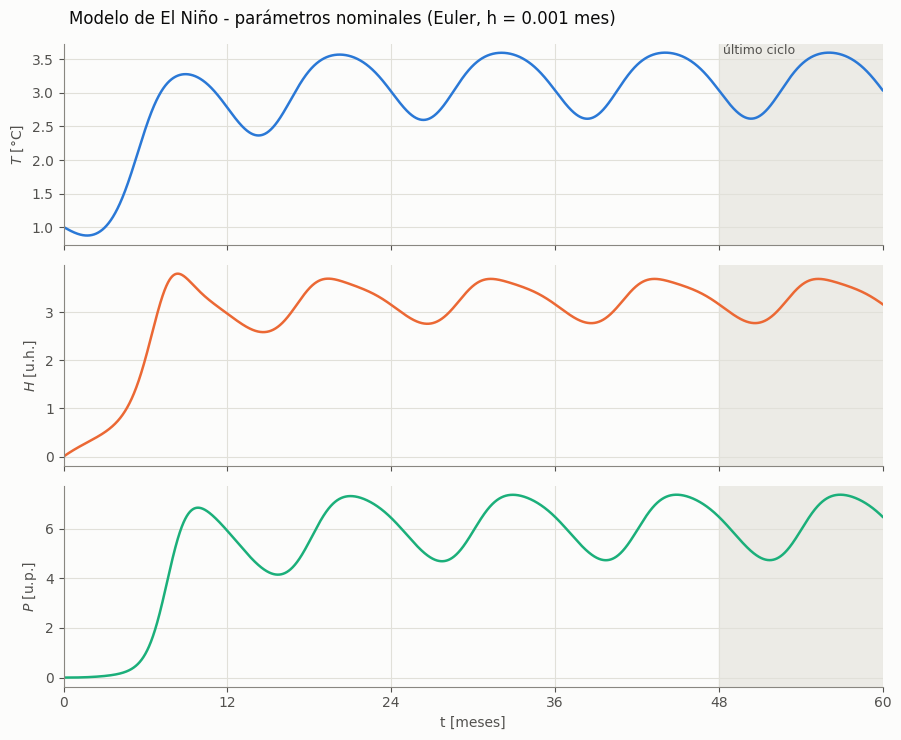

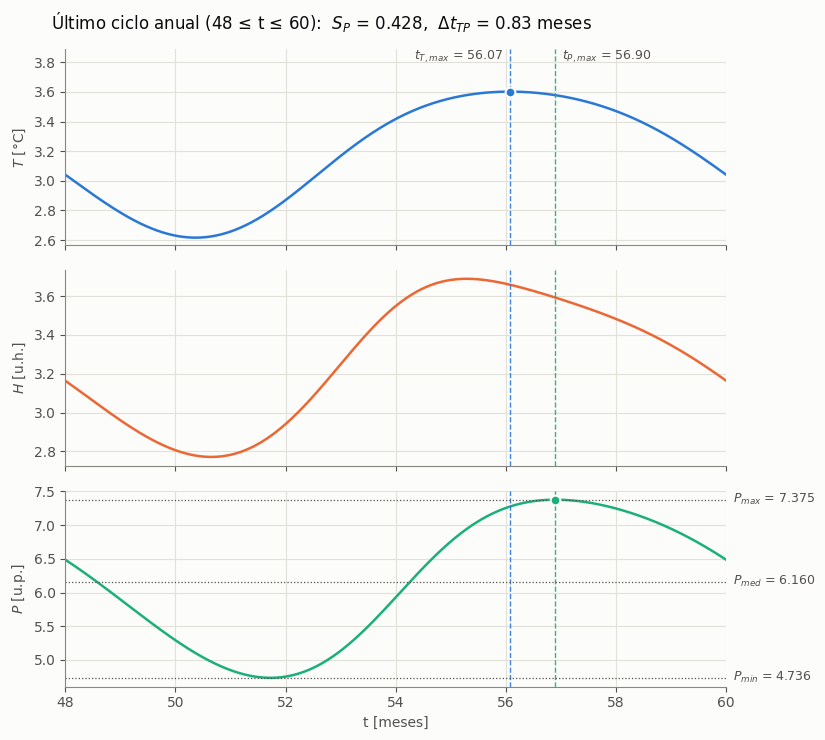

In [14]:
nom = evaluar(con(), H_PARTE2)
print("Euler explícito, h = %g mes, último ciclo 48 <= t <= 60" % H_PARTE2)
print("  Pmax = %.4f   Pmin = %.4f   Pmed = %.4f" % (nom["Pmax"], nom["Pmin"], nom["Pmed"]))
print("  S_P  = (Pmax - Pmin)/Pmed = %.4f" % nom["SP"])
print("  t(Tmax) = %.2f   t(Pmax) = %.2f   dt_TP = %.2f meses" % (nom["tT"], nom["tP"], nom["dtTP"]))
print("  Régimen repetitivo: desvío relativo del último ciclo vs. el anterior = %.1e" % nom["desvio_rel"])

grafico_60_meses(nom["_t"], nom["_y"], H_PARTE2, "fig_3_1_60meses.png")
grafico_ultimo_ciclo(nom["_t"], nom["_y"], nom, "fig_3_1_ultimo_ciclo.png")

## 2.2. Influencia de cada parámetro (Figura 7)

Se modifica **un parámetro por vez**, manteniendo los demás en su valor nominal, en los intervalos de la consigna ($A$: 0,25 a 0,60; $\beta$: 0,10 a 0,30; $\gamma$: 0,05 a 0,20; $\sigma$: 0,40 a 1,00), con 15 valores equiespaciados por parámetro. Como $S_P$ es un cociente, se imprimen también $P_{med}$ y la amplitud $P_{max} - P_{min}$ para saber si $S_P$ cambia porque cambia la oscilación o porque cambia el promedio.

 param    intervalo                S_P      dt_TP [meses]              P_med          Pmax-Pmin
     A  [0.25, 0.6]   0.2154 -> 0.6267     0.958 -> 0.740      6.414 -> 5.881      1.382 -> 3.686  
  beta   [0.1, 0.3]   0.3392 -> 0.4854     1.313 -> 0.687      4.151 -> 7.683      1.408 -> 3.729  
 gamma  [0.05, 0.2]   0.5487 -> 0.3340     1.178 -> 0.670      8.903 -> 4.158      4.885 -> 1.389  
 sigma     [0.4, 1]   0.3408 -> 0.4806     1.197 -> 0.774      7.870 -> 5.229      2.682 -> 2.513  


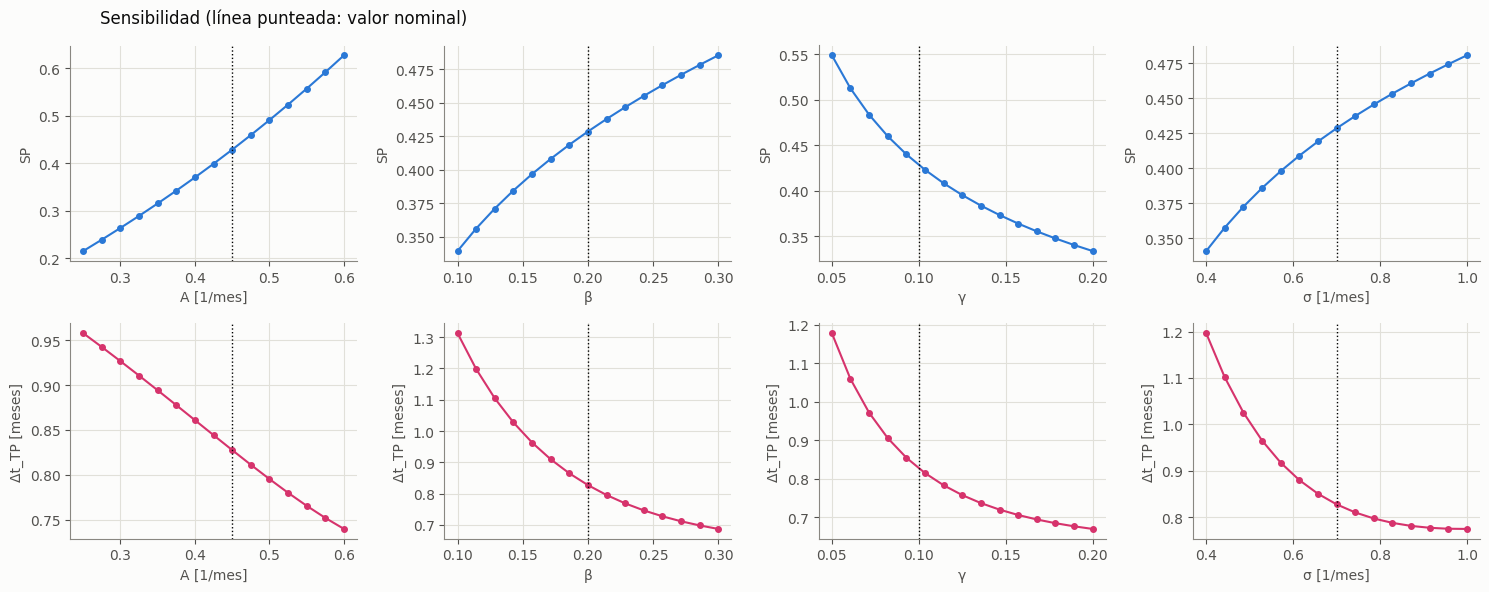

In [15]:
barrido = {}
filas_csv = []
for k, (a, b) in RANGOS.items():
    q = np.linspace(a, b, N_BARRIDO)
    inds = [evaluar(con(**{k: v}), H_PARTE2) for v in q]
    barrido[k] = (q, inds)
    for v, i in zip(q, inds):
        filas_csv.append([k, "%.5f" % v, "%.5f" % i["SP"], "%.4f" % i["dtTP"],
                          "%.5f" % i["Pmax"], "%.5f" % i["Pmin"], "%.5f" % i["Pmed"]])

print("%6s %12s %18s %18s %18s %18s" % ("param", "intervalo", "S_P", "dt_TP [meses]", "P_med", "Pmax-Pmin"))
for k, (q, inds) in barrido.items():
    i0, i1 = inds[0], inds[-1]
    print("%6s %12s %8.4f -> %-7.4f %8.3f -> %-7.3f %8.3f -> %-7.3f %8.3f -> %-7.3f" % (
        k, "[%g, %g]" % RANGOS[k], i0["SP"], i1["SP"], i0["dtTP"], i1["dtTP"],
        i0["Pmed"], i1["Pmed"], i0["amplitud"], i1["amplitud"]))

with open(os.path.join(DIR_RESULTADOS, "tabla_3_2_sensibilidad.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["parametro", "valor", "SP", "dtTP", "Pmax", "Pmin", "Pmed"])
    w.writerows(filas_csv)

fig, ax = plt.subplots(2, 4, figsize=(15, 6))
for j, (k, (q, inds)) in enumerate(barrido.items()):
    ax[0, j].plot(q, [i["SP"] for i in inds], "o-", color=C_T, ms=4)
    ax[1, j].plot(q, [i["dtTP"] for i in inds], "o-", color="#d6336c", ms=4)
    for r in (0, 1):
        ax[r, j].axvline(PARAMS_NOMINALES[k], color="k", ls=":", lw=1)
        ax[r, j].set_xlabel(ETIQ[k])
    ax[0, j].set_ylabel("SP"); ax[1, j].set_ylabel("Δt_TP [meses]")
fig.suptitle("Sensibilidad (línea punteada: valor nominal)", x=0.07, ha="left")
fig.tight_layout()
guardar(fig, "fig_3_2_sensibilidad.png")

**Interpretación a partir de los términos de las ecuaciones** (es una lectura consistente con los datos; los datos muestran la tendencia, no demuestran el mecanismo):

- $A$ está en $R(t)$: una modulación estacional más fuerte hace oscilar más a $T$ y esa oscilación se transmite a $H$ y $P$. $S_P$ crece de forma casi lineal con $A$.
- $\beta$ multiplica la fuente de humedad $+\beta T^2$: más humedad produce más lluvia vía $\delta H^2$. Crecen $P_{med}$ y la amplitud.
- $\gamma$ multiplica el sumidero $-\gamma H P$: cuanto mayor es, más humedad consume la lluvia, y $H$ y $P$ quedan más chicos y con menos contraste. $S_P$ disminuye con $\gamma$.
- $\sigma$ multiplica el sumidero $-\sigma P$: con $\sigma$ grande, $P$ decae rápido y sigue más de cerca a $H$ (menos inercia), lo que adelanta su máximo ($\Delta t_{TP}$ disminuye) y reduce su promedio; la amplitud casi no cambia y $S_P$ sube porque baja $P_{med}$.

## 2.3. Combinaciones de los factores: búsqueda de la mayor severidad (Figura 8)

Se explora una **grilla discreta** de $7 \times 7 \times 7 \times 7 = 2.401$ combinaciones de $A$, $\beta$, $\gamma$ y $\sigma$ dentro de sus intervalos, simulando cada una con $h = 0{,}001$. Una combinación es **válida** si la solución es acotada y si el régimen anual se repite al final (diferencia relativa máxima entre los dos últimos ciclos menor al 1 %). Entre las válidas se busca la de mayor $S_P$.

Esta celda tarda unos minutos (con `RAPIDO = True` usa $h = 0{,}01$ en la grilla). La Figura 8 muestra $S_P$ en el plano $(\gamma, A)$ con $\beta$ y $\sigma$ en su valor óptimo.

2401 combinaciones, h = 0.001 mes ...


Listo en 267 s. Válidas: 2401 de 2401 (descartadas: 0)

Las cinco combinaciones de mayor severidad:
     S_P      A   beta  gamma  sigma      dt_TP
  0.9908  0.600  0.300  0.050  1.000      0.894
  0.9619  0.600  0.300  0.050  0.900      0.879
  0.9509  0.600  0.267  0.050  1.000      0.970
  0.9288  0.600  0.300  0.050  0.800      0.874
  0.9248  0.600  0.267  0.050  0.900      0.957


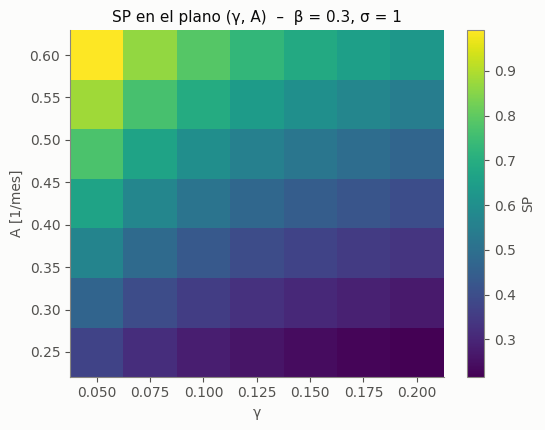


Mejor combinación: A = 0.60, beta = 0.30, gamma = 0.05, sigma = 1.00  ->  S_P = 0.9908


In [16]:
h_grilla = 0.01 if RAPIDO else H_PARTE2
vals = {k: np.linspace(a, b, N_GRILLA) for k, (a, b) in RANGOS.items()}
print("%d combinaciones, h = %g mes ..." % (N_GRILLA ** 4, h_grilla))
t0 = time.time()
filas_g, invalidas = [], 0
for A_, be, ga, si in itertools.product(*vals.values()):
    ind = evaluar(con(A=A_, beta=be, gamma=ga, sigma=si), h_grilla)
    if ind is None or ind["desvio_rel"] > TOL_PERIODICO or not np.isfinite(ind["SP"]):
        invalidas += 1
        continue
    filas_g.append((ind["SP"], A_, be, ga, si, ind["dtTP"], ind["desvio_rel"]))
filas_g.sort(reverse=True)
print("Listo en %.0f s. Válidas: %d de %d (descartadas: %d)\n" % (time.time() - t0, len(filas_g), N_GRILLA ** 4, invalidas))

print("Las cinco combinaciones de mayor severidad:")
print("%8s %6s %6s %6s %6s %10s" % ("S_P", "A", "beta", "gamma", "sigma", "dt_TP"))
for f in filas_g[:5]:
    print("%8.4f %6.3f %6.3f %6.3f %6.3f %10.3f" % (f[0], f[1], f[2], f[3], f[4], f[5]))

with open(os.path.join(DIR_RESULTADOS, "tabla_3_3_grilla.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["SP", "A", "beta", "gamma", "sigma", "dtTP", "desvio_rel"])
    w.writerows([["%.6g" % x for x in fila] for fila in filas_g])

mejor = filas_g[0]
mejor_p = dict(A=mejor[1], beta=mejor[2], gamma=mejor[3], sigma=mejor[4])
mapa = np.full((N_GRILLA, N_GRILLA), np.nan)
for sp, A_, be, ga, si, _, _ in filas_g:
    if abs(be - mejor[2]) < 1e-9 and abs(si - mejor[4]) < 1e-9:
        mapa[int(np.argmin(abs(vals["A"] - A_))), int(np.argmin(abs(vals["gamma"] - ga)))] = sp
fig, ax = plt.subplots(figsize=(5.6, 4.4))
mg = (RANGOS["gamma"][1] - RANGOS["gamma"][0]) / (N_GRILLA - 1) / 2
mA = (RANGOS["A"][1] - RANGOS["A"][0]) / (N_GRILLA - 1) / 2
im = ax.imshow(mapa, origin="lower", aspect="auto", cmap="viridis",
               extent=[RANGOS["gamma"][0] - mg, RANGOS["gamma"][1] + mg, RANGOS["A"][0] - mA, RANGOS["A"][1] + mA])
ax.grid(False)
ax.set_xlabel("γ"); ax.set_ylabel("A [1/mes]")
ax.set_title("SP en el plano (γ, A)  –  β = %g, σ = %g" % (mejor[2], mejor[4]))
fig.colorbar(im, ax=ax, label="SP")
fig.tight_layout()
guardar(fig, "fig_3_3_mapa_SP.png")
print("\nMejor combinación: A = %.2f, beta = %.2f, gamma = %.2f, sigma = %.2f  ->  S_P = %.4f" % (
    mejor[1], mejor[2], mejor[3], mejor[4], mejor[0]))

## 2.4. Comparación de casos (Figuras 9 y 10)

Se compara el escenario de mayor severidad con el caso nominal (parámetros, $S_P$, $\Delta t_{TP}$, $P_{max}$, $P_{min}$ y $P_{med}$ del último ciclo) y se grafican ambos. Luego se responde si ese escenario corresponde a **tomar todos los parámetros en su valor máximo**: se evalúa esa combinación y, partiendo del escenario severo, se lleva de a un parámetro al extremo opuesto de su intervalo.

                Nominal   Mayor sev.
           A       0.45         0.60
        beta       0.20         0.30
       gamma       0.10         0.05
       sigma       0.70         1.00
          SP     0.4285       0.9908
        dtTP     0.8274       0.8938
        Pmax     7.3752      12.6494
        Pmin     4.7360       4.3301
        Pmed     6.1596       8.3965

Régimen repetitivo del escenario severo: desvío relativo = 5.5e-04
La severidad se multiplica por 2.3


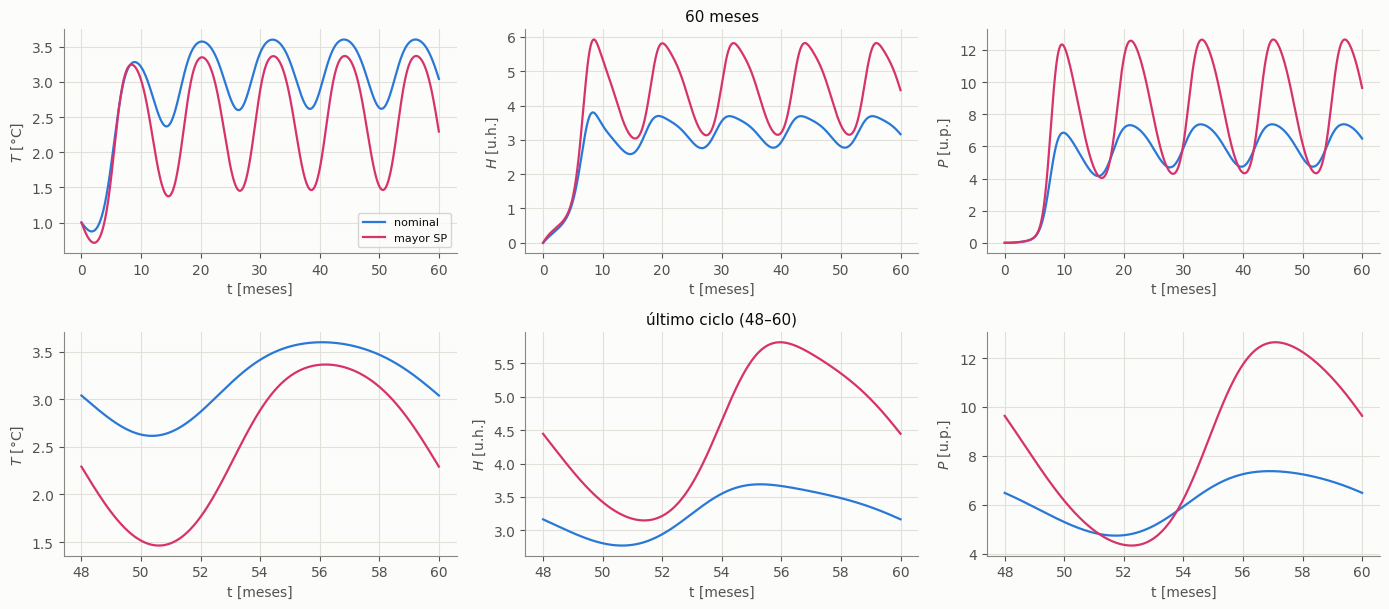

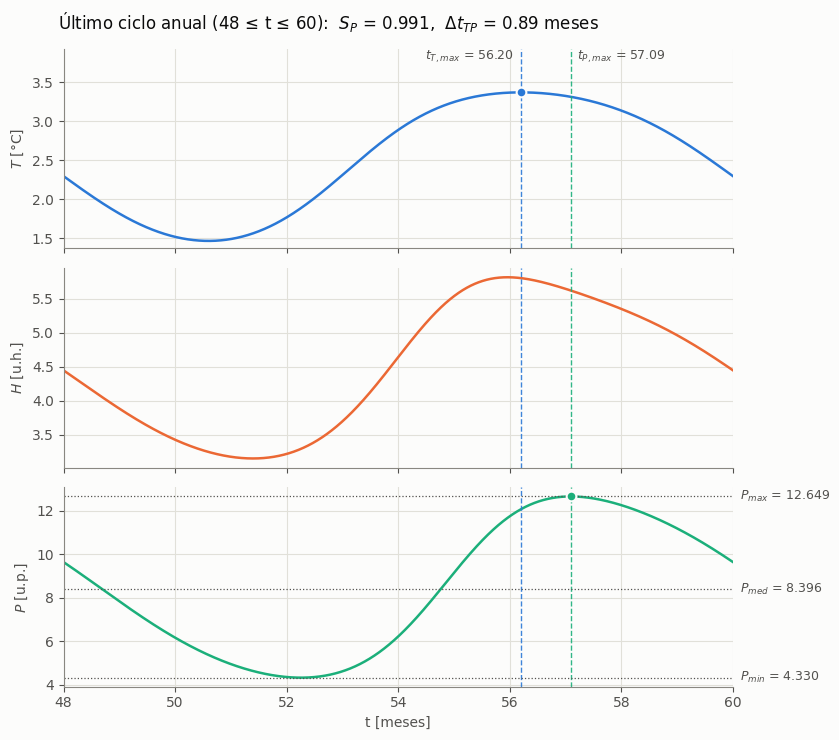

In [17]:
opt = evaluar(con(**mejor_p), H_PARTE2)
print("%12s %10s %12s" % ("", "Nominal", "Mayor sev."))
for k in ("A", "beta", "gamma", "sigma"):
    print("%12s %10.2f %12.2f" % (k, PARAMS_NOMINALES[k], mejor_p[k]))
for k in ("SP", "dtTP", "Pmax", "Pmin", "Pmed"):
    print("%12s %10.4f %12.4f" % (k, nom[k], opt[k]))
print("\nRégimen repetitivo del escenario severo: desvío relativo = %.1e" % opt["desvio_rel"])
print("La severidad se multiplica por %.1f" % (opt["SP"] / nom["SP"]))

fig, ax = plt.subplots(2, 3, figsize=(14, 6.2))
for fila, (a, b, tit) in enumerate([(0, 60, "60 meses"), (48, 60, "último ciclo (48–60)")]):
    for col, (j, (_, etiq, _)) in enumerate(zip(range(3), SERIES)):
        m = (nom["_t"] >= a - 1e-9) & (nom["_t"] <= b + 1e-9)
        ax[fila, col].plot(nom["_t"][m], nom["_y"][m, j], color=C_T, lw=1.6, label="nominal")
        ax[fila, col].plot(opt["_t"][m], opt["_y"][m, j], color="#d6336c", lw=1.6, label="mayor SP")
        ax[fila, col].set_ylabel(etiq); ax[fila, col].set_xlabel("t [meses]")
    ax[fila, 1].set_title(tit)
ax[0, 0].legend(fontsize=8)
fig.tight_layout()
guardar(fig, "fig_3_4_comparacion.png")

grafico_ultimo_ciclo(opt["_t"], opt["_y"], opt, "fig_3_4_ultimo_ciclo_severo.png")

In [18]:
# ¿Es el escenario de mayor severidad "todo al máximo"?
maximos = {k: RANGOS[k][1] for k in RANGOS}
todo_max = evaluar(con(**maximos), H_PARTE2)
print("Todo en su valor máximo (A=0,60; β=0,30; γ=0,20; σ=1,00): S_P = %.4f  (escenario severo: %.4f)" % (todo_max["SP"], opt["SP"]))

print("\nDesde el escenario severo, un parámetro al extremo opuesto (Tabla 11):")
print("%12s %12s %8s %10s" % ("parámetro", "nuevo valor", "S_P", "variación"))
for k in RANGOS:
    otro = RANGOS[k][0] if abs(mejor_p[k] - RANGOS[k][1]) < 1e-9 else RANGOS[k][1]
    i = evaluar(con(**{**mejor_p, k: otro}), H_PARTE2)
    print("%12s %12g %8.4f %+10.4f" % (k, otro, i["SP"], i["SP"] - opt["SP"]))

Todo en su valor máximo (A=0,60; β=0,30; γ=0,20; σ=1,00): S_P = 0.6259  (escenario severo: 0.9908)

Desde el escenario severo, un parámetro al extremo opuesto (Tabla 11):
   parámetro  nuevo valor      S_P  variación
           A         0.25   0.3729    -0.6179


        beta          0.1   0.6370    -0.3538
       gamma          0.2   0.6259    -0.3649


       sigma          0.4   0.7089    -0.2819


**Conclusión.** El escenario de mayor severidad **no** es "todo al máximo": $A$, $\beta$ y $\sigma$ están en su máximo, pero $\gamma$ está en su **mínimo**. Justificación por el signo y la función de cada término:

- $A$ (en $R(t)$) refuerza la oscilación estacional de la cadena $T \to H \to P$.
- $\beta$ (término $+\beta T^2$) es la fuente de humedad que alimenta la lluvia a través de $+\delta H^2$.
- $\sigma$ (término $-\sigma P$) es un sumidero de $P$, pero con $\sigma$ grande $P$ responde rápido a $H$ y su promedio baja, lo que aumenta el cociente $S_P$.
- $\gamma$ (término $-\gamma H P$) es un sumidero de $H$ que actúa cuando hay lluvia y atenúa los picos: su efecto sobre $S_P$ es de signo opuesto al de los otros tres.

Hay que distinguir entre parámetros que **alimentan o amplifican** la cadena ($A$, $\beta$), parámetros que **disminuyen el promedio** de lluvia ($\sigma$) y parámetros que **amortiguan** ($\gamma$).

In [19]:
archivos = sorted(f for f in os.listdir(DIR_RESULTADOS) if f.startswith("fig_"))
print("Figuras en %s/:" % DIR_RESULTADOS)
for f in archivos:
    print("  ", f)

Figuras en resultados/:
   fig_1_2_errores.png
   fig_1_3_orden.png
   fig_1_4_estabilidad.png
   fig_1_4_jacobiano.png
   fig_2_1_autovalores.png
   fig_2_1_euler_h01.png
   fig_3_1_60meses.png
   fig_3_1_ultimo_ciclo.png
   fig_3_2_sensibilidad.png
   fig_3_3_mapa_SP.png
   fig_3_4_comparacion.png
   fig_3_4_ultimo_ciclo_severo.png
